In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling configurations for professional charts
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("Visualizations libraries loaded and styling applied successfully!")

Visualizations libraries loaded and styling applied successfully!


In [11]:
# ------------------------------------------
# 2. Load and Prepare Data (Direct Path)
# ------------------------------------------
countries = ["US", "GB", "IN"]
dfs = []
for code in countries:
    # Read directly from the local data folder
    df_temp = pd.read_csv(f"data/{code}videos.csv")
    df_temp['country'] = code
    dfs.append(df_temp)

df = pd.concat(dfs, ignore_index=True)

# Load categories lookup and merge
categories_df = pd.read_csv("data/categories.csv")
categories_df['category_id'] = categories_df['category_id'].astype(str)
df['category_id'] = df['category_id'].astype(str)

df = pd.merge(df, categories_df[['category_id', 'category_name']], on='category_id', how='left')
df['description'] = df['description'].fillna("")

# Engagement Score & Log Views Feature Engineering
views = df["views"].to_numpy(dtype=float)
likes = df["likes"].fillna(0).to_numpy(dtype=float)
comment_count = df["comment_count"].fillna(0).to_numpy(dtype=float)

def min_max_scale(arr):
    min_val, max_val = np.min(arr), np.max(arr)
    return (arr - min_val) / (max_val - min_val) if max_val - min_val > 0 else np.zeros_like(arr)

df["engagement_score"] = (0.40 * min_max_scale(views)) + (0.40 * min_max_scale(likes)) + (0.20 * min_max_scale(comment_count))
df["log_views"] = np.log1p(views)

print(f"Dataset ready for EDA! Shape: {df.shape}")

Dataset ready for EDA! Shape: (46230, 20)


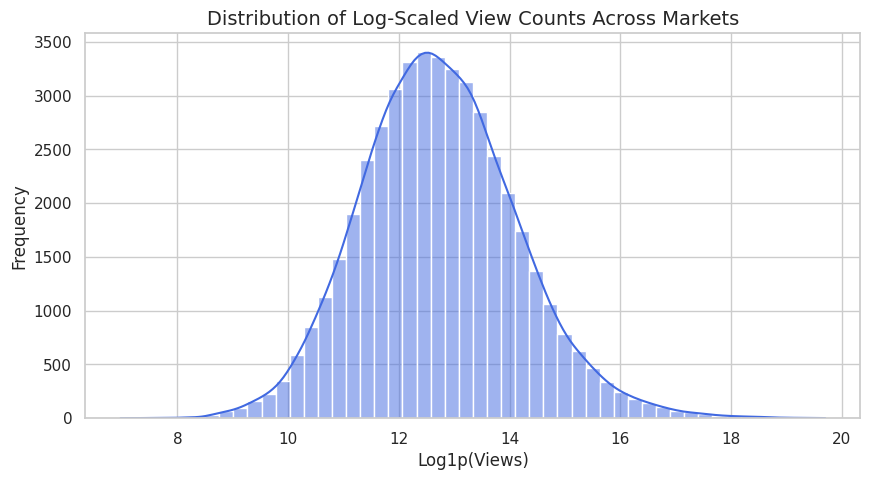

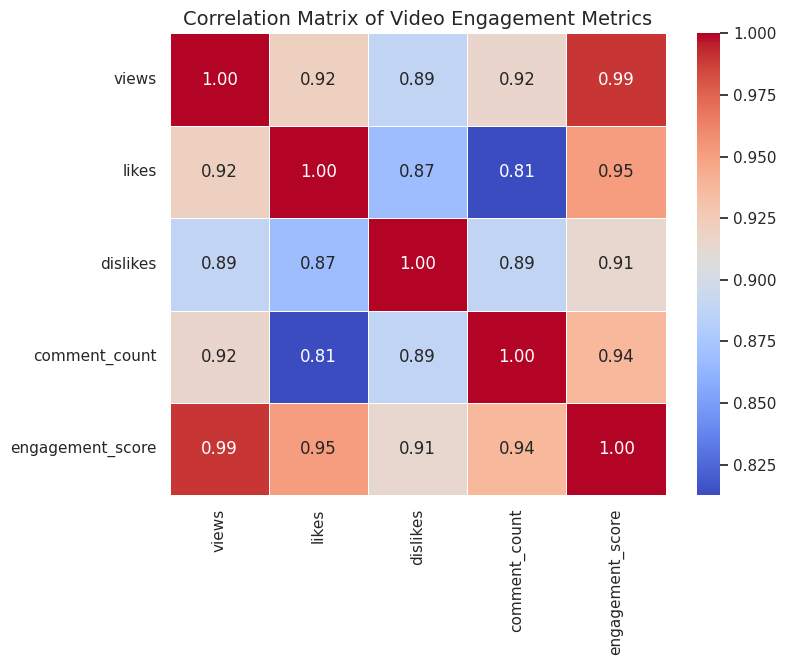

In [15]:
# 1. Distribution of Log-Views (Highlighting skewness)
plt.figure(figsize=(10, 5))
sns.histplot(df['log_views'], bins=50, kde=True, color='royalblue')
plt.title("Distribution of Log-Scaled View Counts Across Markets")
plt.xlabel("Log1p(Views)")
plt.ylabel("Frequency")
plt.savefig("log_views_distribution.png", dpi=300, bbox_inches='tight')
plt.show()
# 2. Correlation Heatmap of Key Numerical Metrics
plt.figure(figsize=(8, 6))
numeric_cols = ['views', 'likes', 'dislikes', 'comment_count', 'engagement_score']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Video Engagement Metrics")
plt.savefig("engagement_correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

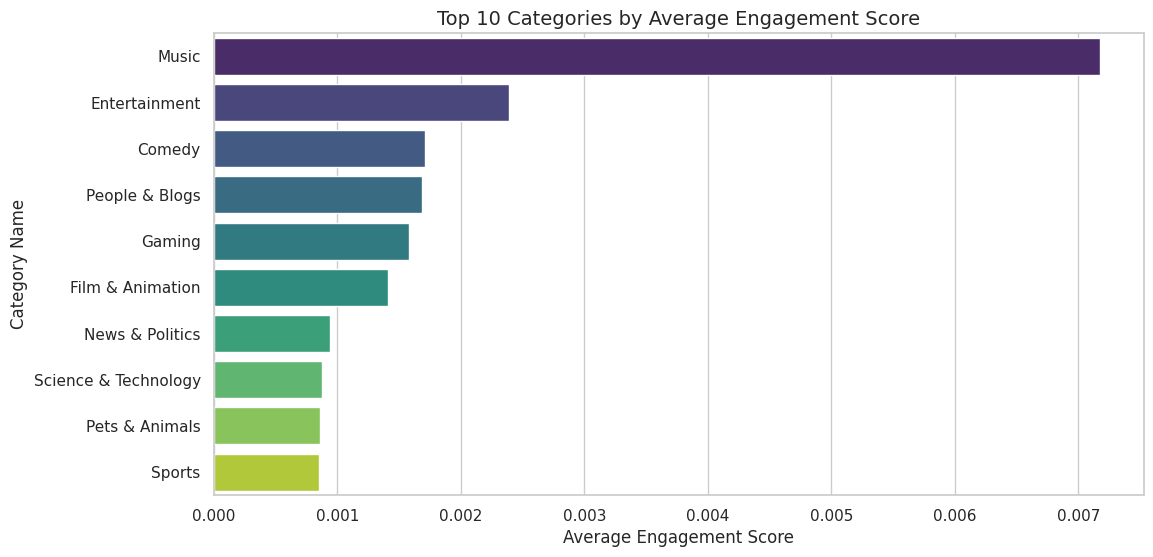

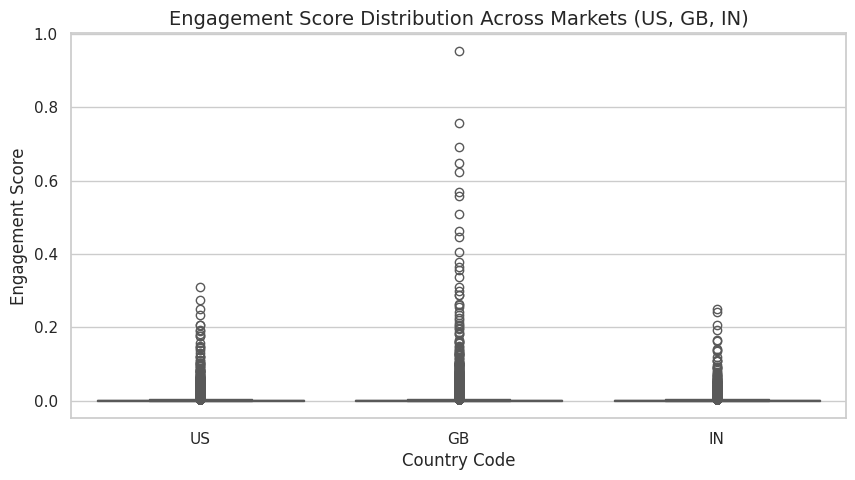

In [16]:
# Plot 3: Top Categories by Average Engagement Score
plt.figure(figsize=(12, 6))
top_categories = df.groupby('category_name')['engagement_score'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis', hue=top_categories.index, legend=False)
plt.title("Top 10 Categories by Average Engagement Score")
plt.xlabel("Average Engagement Score")
plt.ylabel("Category Name")
plt.savefig("top_categories_engagement.png", dpi=300, bbox_inches='tight')
plt.show()

# Plot 4: Engagement Score Distribution Across Markets (Boxplot)
plt.figure(figsize=(10, 5))
sns.boxplot(x='country', y='engagement_score', data=df, palette='Set2', hue='country', legend=False)
plt.title("Engagement Score Distribution Across Markets (US, GB, IN)")
plt.xlabel("Country Code")
plt.ylabel("Engagement Score")
plt.savefig("engagement_by_country_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()